Dawson Conlon

Ricky Doucette

Murry Evans

In [1]:
import pathlib as path
import numpy as np
import pandas as pd
import random as rand
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn as sk
from sklearn import cluster
import hdbscan as hd

In [2]:
#Naming the csv files to a pandas dataframe
customers = pd.read_csv("/Users/dawsonconlon/mdsa/data601/lecture/data/E-Commerce Sales Analytics/customer_master.csv")
orders = pd.read_csv("/Users/dawsonconlon/mdsa/data601/lecture/data/E-Commerce Sales Analytics/order_items.csv")
sales = pd.read_csv("/Users/dawsonconlon/mdsa/data601/lecture/data/E-Commerce Sales Analytics/ecommerce_sales_customer_analytics_150k.csv")
products = pd.read_csv("/Users/dawsonconlon/mdsa/data601/lecture/data/E-Commerce Sales Analytics/product_catalog.csv")

# What is the dataset 

We have a Ecommerace data set with over 150K transactions that collects data on product, marketing, deliveries custumer loyalty etc

We will be focusing on the delivery category of this data trying to get an understanding of what is happening with the shipping side of this company.


The features  of intrest are 

    Delivery_Status: this tell us if a delivery was on time, delayed, canceled and early. 

    Shipping cost: how much do customers pay for shipping based on what they order




If an order is on time, then estimated delivery days = delivery days 

if its late estimated delivery days does not =  delivery days 

In [ ]:
#Merge the data that we can look into shipping features
shipping.df = sales[['order_id', 'customer_id', 'warehouse', 'estimated_delivery_days', 'delivery_days', 'shipping_method', 'delivery_status']].merge(
    orders_prods[['order_id', 'quantity', 'profit', 'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost']],
    on='order_id',
    how='inner'
)

/var/folders/hv/tj8zjgyd3qncstnpt_ttykgr0000gn/T/ipykernel_13748/391960988.py:2: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  shipping.df = sales[['order_id', 'customer_id', 'warehouse', 'estimated_delivery_days', 'delivery_days', 'shipping_method', 'delivery_status']].merge(


In [103]:
#Take a look at the data types
shipping.df.dtypes

order_id                    object
customer_id                 object
warehouse                   object
estimated_delivery_days    float64
delivery_days              float64
shipping_method             object
delivery_status             object
quantity                     int64
profit                     float64
gross_sales                float64
discount_amount            float64
tax_amount                 float64
shipping_cost              float64
net_sales                  float64
product_cost               float64
dtype: object

## The data types we are dealing with 

### Catagorical
    warhouse
    shipping_method 
    delivery_status

### Numerical
    estimated_delivery_days
    delivery_days
    quantity
    profit
    gross_sales
    discount_amount
    tax_amount
    shipping_cost
    net_sales
    product_cost
    





We are dealing with alot numerical datatypes but our feature of intrest is catagorical

# Summary Stats

We want to compute some summary statistics on shipping_cost and delivery_days 

This will give insights into questions such as, are people who pay more for shipping getting there delivery faster than those who do not. 



In [104]:
#Descriptive statistics on shippign cost 
shipping.df["shipping_cost"].describe()

count    397569.000000
mean          8.409010
std           6.777155
min           0.000000
25%           3.370000
50%           5.870000
75%          12.460000
max          36.460000
Name: shipping_cost, dtype: float64

In [105]:
#Descriptive statstics on delivery days
shipping.df["delivery_days"].describe()

count    327028.000000
mean          4.554130
std           2.812564
min           0.000000
25%           2.000000
50%           4.000000
75%           7.000000
max          14.000000
Name: delivery_days, dtype: float64

In [106]:
#Calculate the median shipping cost
median_ship = shipping.df['shipping_cost'].median()

print(f"The medain cost of a shipment for all deliveries is {median_ship} $.")

The medain cost of a shipment for all deliveries is 5.87 $.


In [ ]:
#Calculate the median days to deliver
median_delivery_days = shipping.df['delivery_days'].median()

print(f"The median days it takes to deliver a package for all deliveries is {median_delivery_days} days.")

The median days it takes to deliver a package for all deliveries is 4.0 days.


## Interpretation

### For the shipping cost;

    Based on a count of 397,569 shipments

    On average it cost 8.40$ per shipment

    The median cost of a shipment was 5.87$
    
    There is a standard deveation of 6.8$ 

    The cheapest shipment was 0$ (free)

    The most expensive shipment was 36.46$



### For the delivery_days cost;

    Based on a count of 327,028 shipments

    On average it took 4.6 days to deliver a shipment

    The median time to deliver a shipment was 4.0 days
    
    There is a standard deveation of 2.8 days 

    The quickest shipment was 0 (same day)

    The longest shipment was 14.0 days




    

    

# Visualization

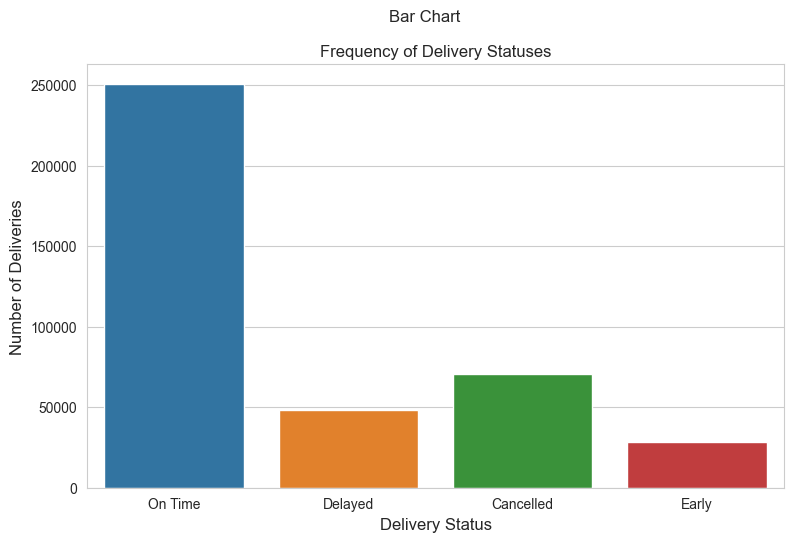

In [ ]:
#Make a bar chart showing the frequency of delivery status catagories

#Set the figure size
plt.figure(figsize=(9, 5.5))

#Make a frequency plot where the color is based on the delivery status
sns.countplot(data = shipping,
              x = "delivery_status",
              hue='delivery_status',
              legend=False)

#Add labels
plt.suptitle('Bar Chart', fontsize = 12)
plt.title("Frequency of Delivery Statuses", fontsize = 12)
plt.xlabel('Delivery Status', fontsize = 12)
plt.ylabel("Number of Deliveries", fontsize = 12)

plt.show()

Bar Chart

1. Data Component

Delivery status of shipped orders is a nominal category.

2. Graphical Component

Bar chart of an obvious choice for a nominal categorical variable. As there is no hierarchy the different categories can only be compared by their frequency of occurrence.

3. Label Component

The x-axis is labeled by the category descriptor, delivery status, while the individual categories are displayed under each bar. The y-axis is labeled frequency. Neither axis has associated units.

4. Esthetic Component

The plot should give a simple visual to compare the frequencies each category occurs with. Comparing height seems more intuitive so frequency was placed on the y-axis.

5. Ethical Component

The exact meaning of canceled deliveries are unclear. If they were canceled because they did not arrive on time it would be more appropriate to include them in the delayed category.

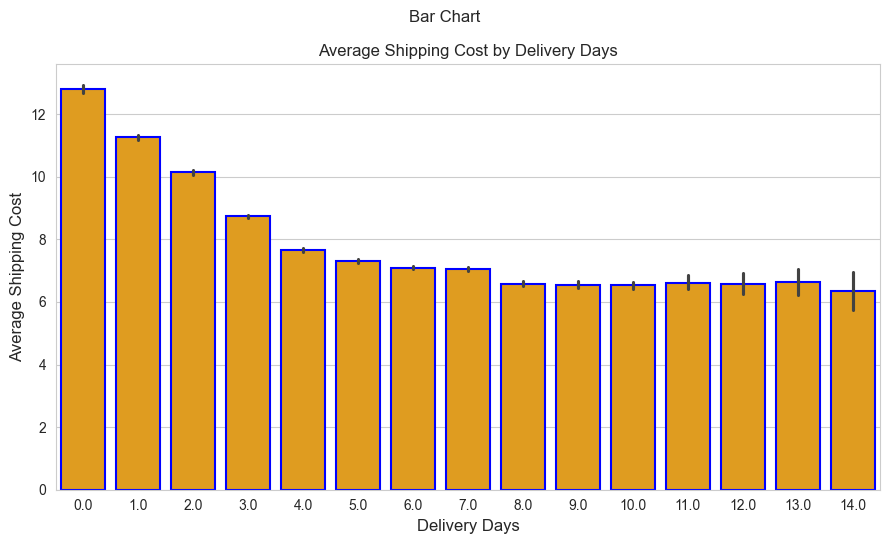

In [ ]:
avg_cost = shipping.groupby('delivery_days')['shipping_cost'].mean()

#Set the figure size
plt.figure(figsize=(9, 5.5))

#Make a bar plot of the average cost of shipping
sns.barplot(data = shipping, 
            x = 'delivery_days',
            y = 'shipping_cost',
            color = 'orange',
            edgecolor = 'blue',
            linewidth = 1.5)

#Add labels
plt.xlabel('Delivery Days', fontsize = 12)
plt.ylabel('Average Shipping Cost', fontsize = 12)
plt.suptitle('Bar Chart', fontsize = 12)
plt.title('Average Shipping Cost by Delivery Days', fontsize = 12)


#Use tight layout to ensure there is no overlap
plt.tight_layout()
plt.show()

Bar Chart

1. Data Component

Average shipping cost in dollars is a continuous numerical variable.
Days taken for delivery is a discrete numerical variable.

2. Graphical Component

A bar chart or a box plot would be the best visualizations to describe the data, we went with a bar chart because it easily showed where the data plateaus and how many days it usually takes this company to ship a package.

3. Label Component

The x-axis label contains the units days, the y-axis label contains the units, dollars, and quantity of measure average shipping cost.

4. Esthetic Component

The plot is trying to capture the question if a customer pays more for shipping, do they get the shipment in a shorter amount of time? The best way to convey this is to make a chart that one can look at and instantly answer that question our bar chart accomplishes this because you look at the bars for 0 to 2 delivery days and you clearly see on average customers paid more to get that quicker shipping.

5. Ethical Component

I do not think that this graph is misleading although there is some context that is left out such as what items are being delivered that take longer maybe electronics take longer to deliver than other items and having a plot that could capture those categories of items and how long they take to deliver could be insightful.

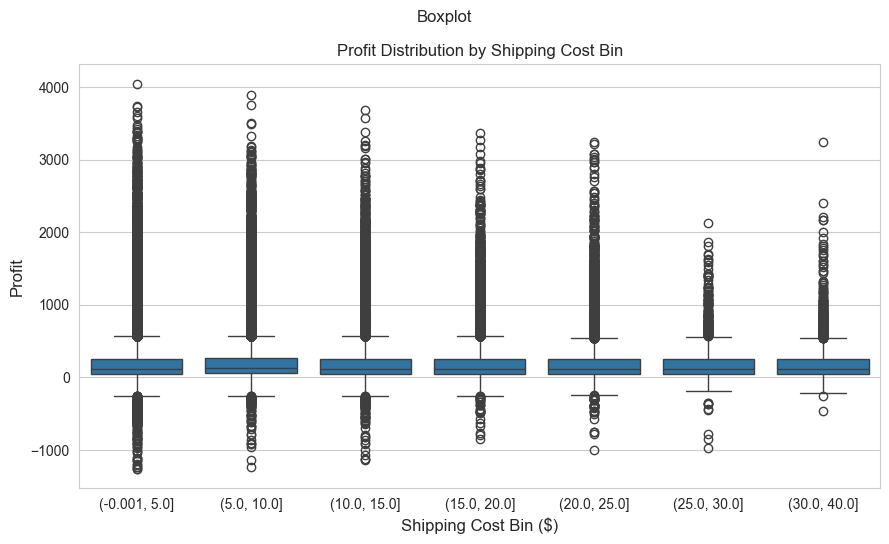

In [125]:
plt.figure(figsize=(9, 5.5))

sns.boxplot(data=shipping,
            x='shipping_cost_bin', 
            y='profit')

plt.xlabel('Shipping Cost Bin ($)', fontsize=12)
plt.ylabel('Profit', fontsize=12)
plt.suptitle('Boxplot', fontsize=12)
plt.title('Profit Distribution by Shipping Cost Bin', fontsize=12)

plt.tight_layout()
plt.show()


Boxplot

1. Data Component

Shipping cost in dollars is a continuous numerical variable.
Profit in dollars is a continuous numerical variable.

1. Graphical Component

A box pot was the best way to get an understanding of these variables because we gotta see where the data sits in their quartiles,  where the median is  and how many outliers there are all by easily looking at this graph.

2. Label Component

The x-axis label contains quantity of measure shipping cost in dollars, the y-axis label contains the units, dollars, and quantity of measure profit.

1. Esthetic Component

 the plot can answer a variety of questions such as are high profit or low profit items cheaper or more expensive to ship, these kinds of questions will be answered by looking at the median line and where the boxes sit on the graph.

1. Ethical Component

 limitation of this graph is that we don't know what items are making  low and high profit it would be nice if we knew what category of item was doing this, there are also many outliers that could be skewing the data.

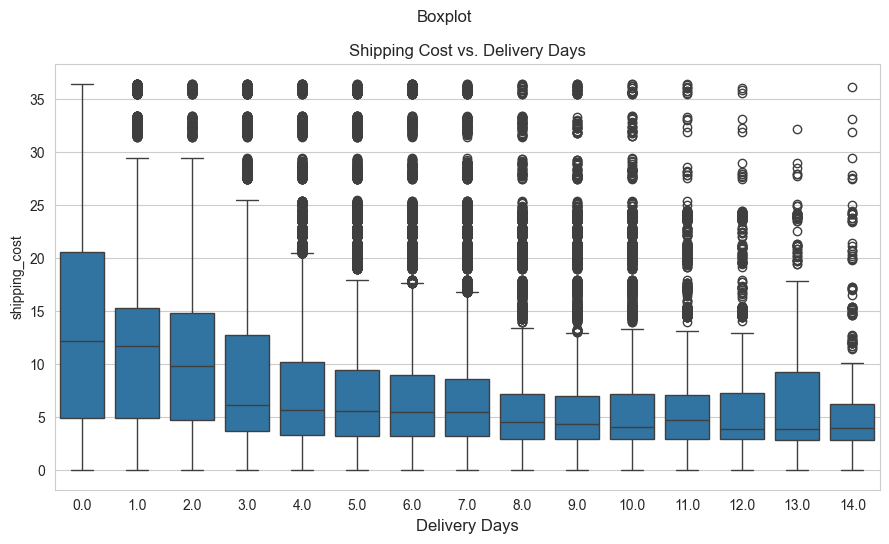

In [135]:

#Set the figure size
plt.figure(figsize=(9, 5.5))

#Make a boxplot of delivery days and shipping cost 
sns.boxplot(data= shipping, 
            x='delivery_days', 
            y='shipping_cost')
plt.title('Shipping Cost vs. Delivery Days')
plt.xlabel("Delivery Days", fontsize = 12)

plt.suptitle("Boxplot", fontsize = 12)

#Use tight layout to ensure there is no overlap
plt.tight_layout()
plt.show()

Boxplot

1. Data Component

Shipping cost in dollars is a continuous numerical variable.
Days taken for delivery is a discrete numerical variable.

2. Graphical Component

Due to the discrete nature of days a scatter plot would not make sense. A plot that can summarize the continuous variable of shipping cost across discrete days is required. A box plot is ideal because it contains many summary statistics in the same plot to allow for comparison of median, spread and outliers at the same time.

3. Label Component

The x-axis label contains the units, days, and total quantity being measured, the time taken for delivery. The y-axis label contains the units, dollars, and quantity of measure shipping cost.

4. Esthetic Component

The plot is meant to investigate if there is a relationship between shipping cost and delivery time. One would expect that paying more for shipping would result in faster delivery on average. This relationship will be best captured by the median line in each box which would be expected to decrease over time. The outliers are also displayed and one would also expect a lower density of high cost points for increasing delivery days.

5. Ethical Component

While the graph does capture a relationship between higher costs and faster shipping it does not account for various other reasons shipping cost may be higher including long distance or international deliveries that would result in higher delivery times.

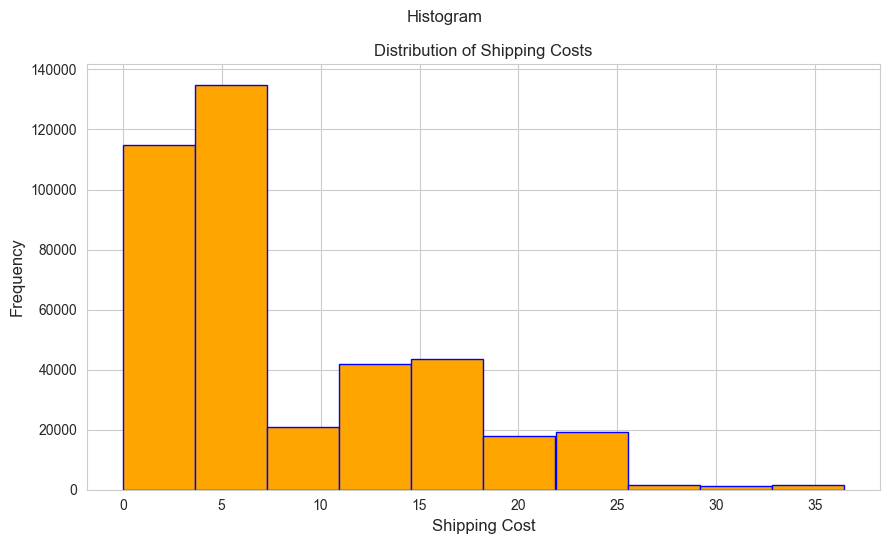

In [134]:

#Set the figure size
plt.figure(figsize=(9, 5.5))

#Make a histogram of shipping cost and frequency
plt.hist(
    shipping['shipping_cost'], 
    edgecolor = 'blue',
    color = 'orange')

#Add labels
plt.xlabel('Shipping Cost',fontsize = 12)
plt.ylabel('Frequency',fontsize = 12)
plt.suptitle("Histogram",fontsize = 12)
plt.title('Distribution of Shipping Costs',fontsize = 12)

plt.tight_layout()
plt.show()

Histogram

1. Data Component

Shipping cost is a numerical continuous variable.

2. Graphical Component

A histogram is best suited for viewing the shape of the distribution of a variable.

3. Label Component

As is customary for a histogram the a-axis contains the variable of interest with the y-axis containing frequency count. The continuous valued shipping cost is placed in discrete bins to give shape to the distribution.

4. Esthetic Component

The plot shows the height of each bin as a frequency in order to fill in the shape of the distribution of the variable of interest, shipping cost. It is a simple visual to determine whether the distribution is normal, skewed, etc. In this case there is a bimodal distribution with most of the data around $5 and a second smaller peak around $15.

5. Ethical Component

The shape of the distribution can appear different for various choices of bin width.

# Coorilation Plots

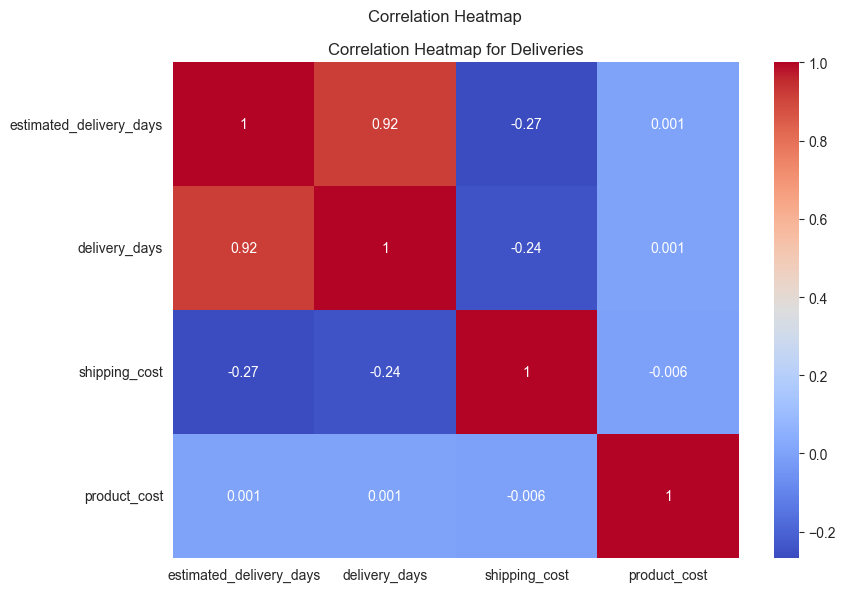

In [ ]:
# Set the figure size
plt.figure(figsize=(9,6))

#Make a heatmap 
sns.heatmap(ship_corr,
            annot=True,
            cmap = 'coolwarm')

#Add titles
plt.suptitle("Correlation Heatmap",fontsize = 12)
plt.title('Correlation Heatmap for Deliveries',fontsize = 12)

#Adjust the layout
plt.tight_layout()
plt.show()

Based on the correlation plot above, estimated delivery days and delivery days has a strong positive correlation. This means that this company has a really effective ability to predict how long a shipment is gonna take to go out and then executing that timeframe.

Shipping cost and delivery days has a week negative correlation this means that orders where customers paid more for shipping somtimes received shorter delivery times, this is a weak negative correlation so this phenomenon does not happen consistently.

Product cost is not really correlated with anything this means that we cannot really make any predictions for delivery times or how much it cost to ship an item based on the price of the item.

# Discussion
Overall the EDA of this dataset was insightfull. We gathered insight on this companys shipping efficiency, and got to see that this company ships most of its orders on time and the company has a strong ability to predict how long a delivery will take to reach a customer. We got to see that if you pay more, you will generally get your order faster, but this phenomenon has a plateau at around seven dollar where at that point a customer could be receiving their shipment in a short amount of time or in a very long amount of time with regards to the maximum and minimum shipping times, and a correlation heat map showed there was a weak negative correlation between these variables. Our box plot showed us that the shipping data has a lot of variation with respect to how much you pay for shipping and how quickly you receive your order, there are cases where people pay very little and receive their shipment in a short amount of time, and there are cases where people pay a lot of money and have to wait a very long amount of time to receive their shipment. We also gathered insights on high profit and low profit item shipping costs, witch from our box plot, showed us that there does not seem to be a relationship regarding item profit and shipping cost.

The data set has limitations with regards to it being synthetic data and not real life cases where we would maybe see higher shipping prices and possibly more delays. The data set also has limitations with regards to description of why orders were late and why orders were cancelled, it would be more valuable if we knew why these orders got cancelled or delayed, and if it was the company's fault, customer preference or maybe weather causing delays for example. 